# Geração das camadas

In [19]:
!pip install whitebox

  Using cached whitebox-2.3.6-py2.py3-none-any.whl.metadata (11 kB)
Using cached whitebox-2.3.6-py2.py3-none-any.whl (74 kB)


In [1]:
import whitebox

wbt = whitebox.WhiteboxTools()

print(wbt.version())

WhiteboxTools v2.4.0 (c) Dr. John Lindsay 2017-2023

WhiteboxTools is an advanced geospatial data analysis platform developed at
the University of Guelph's Geomorphometry and Hydrogeomatics Research 
Group (GHRG). See www.whiteboxgeo.com for more details.



In [1]:
import numpy as np
import rasterio
import matplotlib.pyplot as plt

import rasterio
from rasterio.warp import transform_bounds, reproject, Resampling

import os
import shutil
import tempfile
from pathlib import Path

from whitebox.whitebox_tools import WhiteboxTools

import geopandas as gpd
from rasterio.features import rasterize
from scipy.ndimage import distance_transform_edt
from shapely.geometry import box

import pandas as pd
from scipy.spatial import distance_matrix

In [2]:
class ConfigService:
    def __init__(self, cidade="recife", crs="EPSG:31985"):
        self.cidade = cidade
        self.crs = crs

    def gerar_config(self):
        return {
            "criterios": {
                "uso_do_solo": {"ativo": True, "classes": self._config_uso_do_solo()},
                "declividade": {"ativo": True, "classes": self._config_declividade()},
                "fluxo_acumulado": {"ativo": True, "classes": self._config_fluxo()},
                "hipsometria": {"ativo": True, "classes": self._config_hipsometria()},
                "distancia_rio": {"ativo": True, "classes": self._config_distancia()},
                "hand": {"ativo": True, "classes": self._config_hand()},
                "twi": {"ativo": True, "classes": self._config_twi()},
                "pluviometria": {"ativo": True, "classes": self._config_pluviometria()}
            }
        }

    # USO DO SOLO (Categorizado a partir da Legenda MapBiomas)
    def _config_uso_do_solo(self):
        return {
            "corpo_dagua": {
                "ids": [26, 33, 31],
                "valor": 5.0
            },
            "mangue_e_alagados": {
                "ids": [5, 6, 11, 32],
                "valor": 4.5
            },
            "area_urbana_e_impermeavel": {
                "ids": [22, 23, 24, 25, 30],
                "valor": 3.5
            },
            "agropecuaria_e_culturas": {
                "ids": [14, 15, 18, 19, 39, 20, 40, 62, 41, 36, 46, 47, 35, 48, 9, 21],
                "valor": 2.0
            },
            "floresta_e_vegetacao_natural": {
                "ids": [1, 3, 4, 49, 10, 12, 29, 50],
                "valor": 1.0
            }
        }

    # DECLIVIDADE
    def _config_declividade(self):
        return [
            {"min": 0.0,  "max": 3.0,  "valor": 5.0}, # Plano
            {"min": 3.0,  "max": 8.0,  "valor": 3.5}, # Suave
            {"min": 8.0,  "max": 13.0, "valor": 2.5}, # Moderado
            {"min": 13.0, "max": 20.0, "valor": 1.5}, # Inclinado
            {"min": 20.0, "max": None, "valor": 1.0}  # Íngreme
        ]

    # HIPSOMETRIA
    def _config_hipsometria(self):
        if self.cidade == "recife":
            return [
                {"min": -10.0, "max": 0.0,  "valor": 5.0},
                {"min": 0.0,   "max": 1.0,  "valor": 4.5},
                {"min": 1.0,   "max": 3.0,  "valor": 4.0},
                {"min": 3.0,   "max": 10.0, "valor": 2.5},
                {"min": 10.0,  "max": None, "valor": 1.0}
            ]

    # DISTÂNCIA DOS RIOS
    def _config_distancia(self):
        return [
            {"min": 0.0,    "max": 50.0,   "valor": 5.0},
            {"min": 50.0,   "max": 150.0,  "valor": 4.0},
            {"min": 150.0,  "max": 300.0,  "valor": 3.0},
            {"min": 300.0,  "max": 600.0,  "valor": 2.0},
            {"min": 600.0,  "max": None,   "valor": 1.0}
        ]

    # FLUXO ACUMULADO
    def _config_fluxo(self):
        return [
            {"min": 0.0,     "max": 1000.0,  "valor": 1.0},
            {"min": 1000.0,  "max": 3500.0,  "valor": 2.0},
            {"min": 3500.0,  "max": 8000.0,  "valor": 3.0},
            {"min": 8000.0,  "max": 20000.0, "valor": 4.0},
            {"min": 20000.0, "max": None,    "valor": 5.0}
        ]

    # HAND (Height Above Nearest Drainage)
    def _config_hand(self):
        return [
            {"min": 0.0,  "max": 1.0,  "valor": 5.0}, # Leito e planície imediata
            {"min": 1.0,  "max": 3.0,  "valor": 4.0},
            {"min": 3.0,  "max": 6.0,  "valor": 3.0},
            {"min": 6.0,  "max": 12.0, "valor": 2.0},
            {"min": 12.0, "max": None, "valor": 1.0}  # Encruzilhadas e encostas altas
        ]

    # TWI
    def _config_twi(self):
        return [
            {"min": 0.0,  "max": 5.0,  "valor": 1.0},
            {"min": 5.0,  "max": 8.0,  "valor": 2.0},
            {"min": 8.0,  "max": 11.0, "valor": 3.0},
            {"min": 11.0, "max": 15.0, "valor": 4.0},
            {"min": 15.0, "max": None, "valor": 5.0}  # Alta tendência ao acúmulo hídrico
        ]

    # PLUVIOMETRIA
    def _config_pluviometria(self):
        return [
            {"min": 0.0,      "max": 150.8883, "valor": 1.0},
            {"min": 150.8883, "max": 156.5367, "valor": 2.0},
            {"min": 156.5367, "max": 167.8333, "valor": 3.0},
            {"min": 167.8333, "max": 173.4817, "valor": 4.0},
            {"min": 173.4817, "max": None,     "valor": 5.0}
        ]

config_service = ConfigService(cidade='recife')
CONFIG = config_service.gerar_config()

In [3]:
def reclassificar_raster(array_dados, regras, nodata=-9999):
    """
    Reclassifica uma matriz numpy com base em uma lista de intervalos ou dicionário categórico.
    Mantém intactos os pixels de NoData.
    """
    reclass = np.full(array_dados.shape, nodata, dtype=np.float32)
    mask_valida = (array_dados != nodata) & (~np.isnan(array_dados))

    # Reclassificação Categórica (Uso do Solo)
    if isinstance(regras, dict):
        for classe_info in regras.values():
            valor_novo = classe_info["valor"]
            ids = classe_info["ids"]
            mask_cat = np.isin(array_dados, ids) & mask_valida
            reclass[mask_cat] = valor_novo

    # Reclassificação Intervalar (Hipsometria, Declividade...)
    elif isinstance(regras, list):
        for regr in regras:
            v_min = regr["min"]
            v_max = regr["max"]
            v_novo = regr["valor"]

            if v_max is None:
                mask_interv = (array_dados >= v_min) & mask_valida
            else:
                mask_interv = (array_dados >= v_min) & (array_dados < v_max) & mask_valida

            reclass[mask_interv] = v_novo

    return reclass

In [4]:
def plotar_comparacao(array_original, array_reclassificado, titulo="Camada", nodata=-9999, cmap_orig="terrain"):
    orig_masked = np.ma.masked_equal(array_original, nodata)
    orig_masked = np.ma.masked_where(np.isnan(orig_masked), orig_masked)

    recl_masked = np.ma.masked_equal(array_reclassificado, nodata)
    recl_masked = np.ma.masked_where((recl_masked < 1) | np.isnan(recl_masked), recl_masked)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6))

    # Plot 1: Original
    im1 = ax[0].imshow(orig_masked, cmap=cmap_orig)
    ax[0].set_title(f"{titulo} (Valores Brutos)", fontsize=11)
    plt.colorbar(im1, ax=ax[0], shrink=0.7)
    ax[0].axis("off")

    # Plot 2: Reclassificado
    im2 = ax[1].imshow(recl_masked, cmap="YlOrRd", vmin=1, vmax=5)
    ax[1].set_title(f"{titulo} (Reclassificado 1-5)", fontsize=11)
    cbar2 = plt.colorbar(im2, ax=ax[1], shrink=0.7, ticks=[1, 2, 3, 4, 5])
    cbar2.ax.set_yticklabels(['1 (Muito Baixa)', '2 (Baixa)', '3 (Média)', '4 (Alta)', '5 (Muito Alta)'])
    ax[1].axis("off")

    plt.tight_layout()
    plt.show()

In [5]:
import matplotlib.pyplot as plt
import numpy as np

def plotar_raster(array, titulo="Raster", nodata=-9999, cmap="terrain", vmin=None, vmax=None, ticks=None, tick_labels=None):
    array_masked = np.ma.masked_equal(array, nodata)
    array_masked = np.ma.masked_where(np.isnan(array_masked), array_masked)

    fig, ax = plt.subplots(figsize=(8, 6))

    im = ax.imshow(array_masked, cmap=cmap, vmin=vmin, vmax=vmax)
    ax.set_title(titulo, fontsize=12)
    
    if ticks is not None and tick_labels is not None:
        cbar = plt.colorbar(im, ax=ax, shrink=0.8, ticks=ticks)
        cbar.ax.set_yticklabels(tick_labels)
    else:
        plt.colorbar(im, ax=ax, shrink=0.8)
        
    ax.axis("off")
    plt.tight_layout()
    plt.show()

In [6]:
def alinhar_raster_ao_mdt(caminho_raster_entrada, mdt_meta, resampling_mode=Resampling.nearest):
    """
    Recorta e reamostra um raster externo para coincidir exatamente com a grade, 
    resolução e extensão do MDT do PE3D.
    
    Use Resampling.nearest para dados categóricos (Uso do Solo).
    Use Resampling.bilinear para dados contínuos.
    """
    with rasterio.open(caminho_raster_entrada) as src_in:
        # Cria a matriz de destino vazia no tamanho exato do MDT
        raster_alinhado = np.full(
            (mdt_meta['height'], mdt_meta['width']), 
            mdt_meta['nodata'], 
            dtype=np.float32
        )
        
        # Reprojeta, reamostra e recorta simultaneamente
        reproject(
            source=rasterio.band(src_in, 1),
            destination=raster_alinhado,
            src_transform=src_in.transform,
            src_crs=src_in.crs,
            dst_transform=mdt_meta['transform'],
            dst_crs=mdt_meta['crs'],
            resampling=resampling_mode,
            dst_nodata=mdt_meta['nodata']
        )
        
    return raster_alinhado


In [7]:
def salvar_raster(array_dados, caminho_saida, mdt_info, dtype='float32'):
    """
    Salva uma matriz NumPy como um arquivo GeoTIFF alinhado aos metadados do MDT.
    
    Parameters:
    - array_dados: np.ndarray contendo a matriz reclassificada/processada.
    - caminho_saida: str contendo o caminho e nome do arquivo de destino (.tif).
    - mdt_info: dict contendo os metadados do MDT (criado na leitura inicial).
    - dtype: tipo de dado para salvar (padrão: 'float32').
    """
    
    os.makedirs(os.path.dirname(caminho_saida), exist_ok=True)
    
    perfil = mdt_info['perfil'].copy() if 'perfil' in mdt_info else {}
    perfil.update({
        'driver': 'GTiff',
        'height': mdt_info['height'],
        'width': mdt_info['width'],
        'transform': mdt_info['transform'],
        'crs': mdt_info['crs'],
        'count': 1,
        'dtype': dtype,
        'nodata': mdt_info['nodata'],
        'compress': 'lzw',
        'tiled': True
    })
    
    with rasterio.open(caminho_saida, 'w', **perfil) as dst:
        dst.write(array_dados.astype(dtype), 1)
        
    print(f"Raster salvo com sucesso em: {caminho_saida}")

In [9]:
# mdt_path = '../dados/camadas_rasters/mdt_recife_pe3d_10m.tif'
mdt_path = '../dados/camadas_rasters/sao-lourenco/mdt_sao_lourenco_pe3d_10m.tif'

with rasterio.open(mdt_path) as src:
    mdt_array = src.read(1).astype(np.float32)
    mdt_perfil = src.profile.copy()
    
    mdt_info = {
        "crs": src.crs,
        "transform": src.transform,
        "bounds": src.bounds,
        "res": src.res,
        "width": src.width,
        "height": src.height,
        "nodata": src.nodata if src.nodata is not None else -9999,
        "dtype": rasterio.float32,
        "bounds_latlon": transform_bounds(src.crs, "EPSG:4326", *src.bounds)
    }

print(f"MDT carregado")
print(f" Matriz: {mdt_info['height']} x {mdt_info['width']} pixels")
print(f" Resolução: {mdt_info['res'][0]}m x {mdt_info['res'][1]}m")
print(f" CRS: {mdt_info['crs']}")

MDT carregado
 Matriz: 1864 x 3114 pixels
 Resolução: 10.002569043031471m x 10.001609442060087m
 CRS: EPSG:31985


## Hipsometria

In [19]:
# Hipsometria é o próprio MDT
hipsometria = mdt_array.copy()

# Reclassifica usando o dicionário CONFIG
regras_hipso = CONFIG['criterios']['hipsometria']['classes']
hipsometria_reclass = reclassificar_raster(hipsometria, regras_hipso, nodata=mdt_info['nodata'])

caminho_hipso = '../dados/camadas_rasters/hipsometria.tif'
caminho_saida_hipso = '../dados/camadas_rasters/hipsometria_reclass.tif'

salvar_raster(hipsometria, caminho_hipso, mdt_info)
salvar_raster(hipsometria_reclass, caminho_saida_hipso, mdt_info)

Raster salvo com sucesso em: ../dados/camadas_rasters/hipsometria.tif
Raster salvo com sucesso em: ../dados/camadas_rasters/hipsometria_reclass.tif


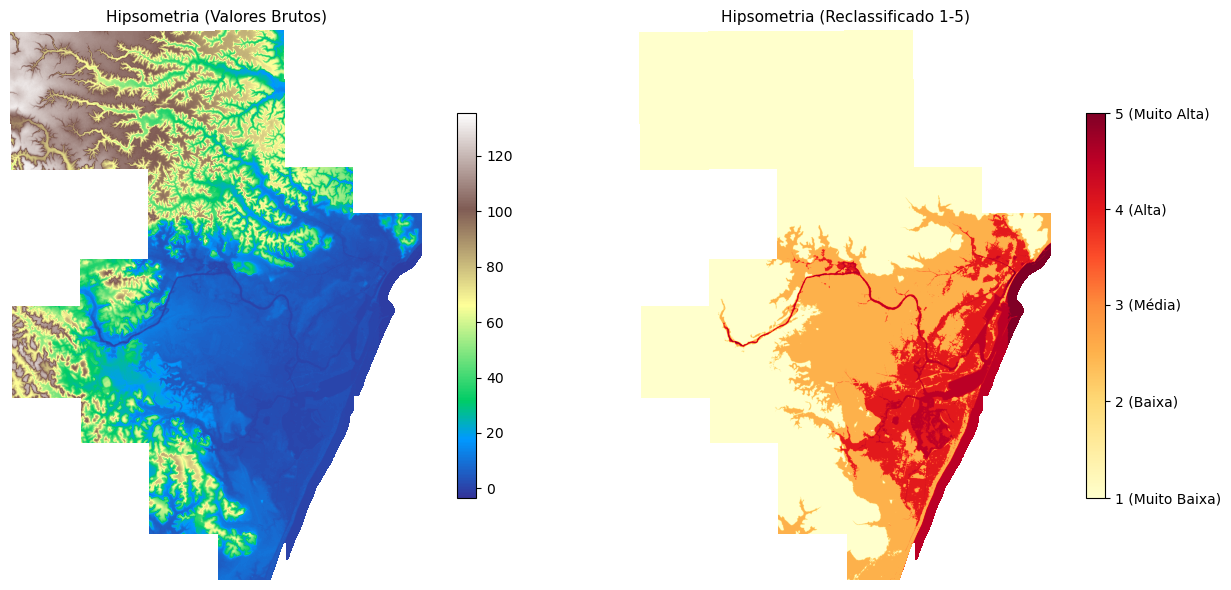

In [14]:
plotar_comparacao(
    array_original=hipsometria,
    array_reclassificado=hipsometria_reclass,
    titulo="Hipsometria",
    nodata=mdt_info['nodata'],
    cmap_orig="terrain"
)

Raster salvo com sucesso em: ../dados/camadas_rasters/sao-lourenco/hipsometria.tif


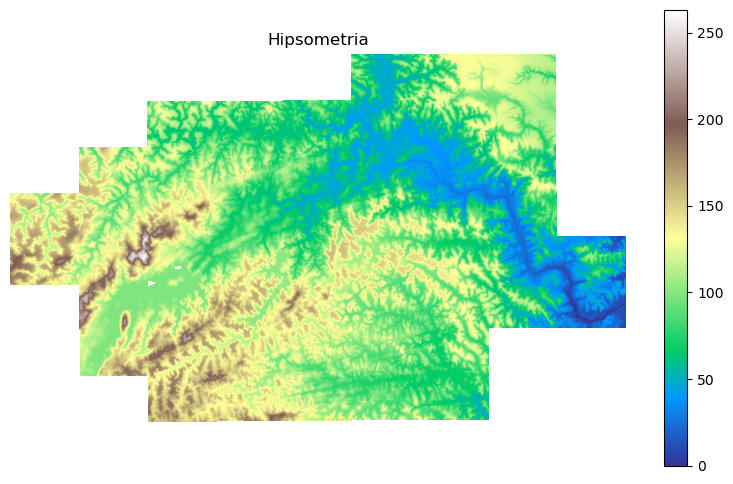

In [9]:
hipsometria = mdt_array.copy()

caminho_hipso = '../dados/camadas_rasters/sao-lourenco/hipsometria.tif'

salvar_raster(hipsometria, caminho_hipso, mdt_info)

plotar_raster(hipsometria, titulo="Hipsometria", nodata=mdt_info['nodata'], cmap="terrain")

## Declividade

In [20]:
xres, yres = mdt_info['res']

mdt_valido = np.where(mdt_array == mdt_info['nodata'], np.nan, mdt_array)
gy, gx = np.gradient(mdt_valido, yres, xres)
declividade_bruta = np.sqrt(gx**2 + gy**2) * 100.0
declividade_bruta[np.isnan(mdt_valido)] = mdt_info['nodata']

regras_declividade = CONFIG['criterios']['declividade']['classes']
declividade_reclass = reclassificar_raster(declividade_bruta, regras_declividade, nodata=mdt_info['nodata'])

caminho_declividade = '../dados/camadas_rasters/declividade.tif'
caminho_saida_declividade = '../dados/camadas_rasters/declividade_reclass.tif'

salvar_raster(declividade_bruta, caminho_declividade, mdt_info)
salvar_raster(declividade_reclass, caminho_saida_declividade, mdt_info)

Raster salvo com sucesso em: ../dados/camadas_rasters/declividade.tif
Raster salvo com sucesso em: ../dados/camadas_rasters/declividade_reclass.tif


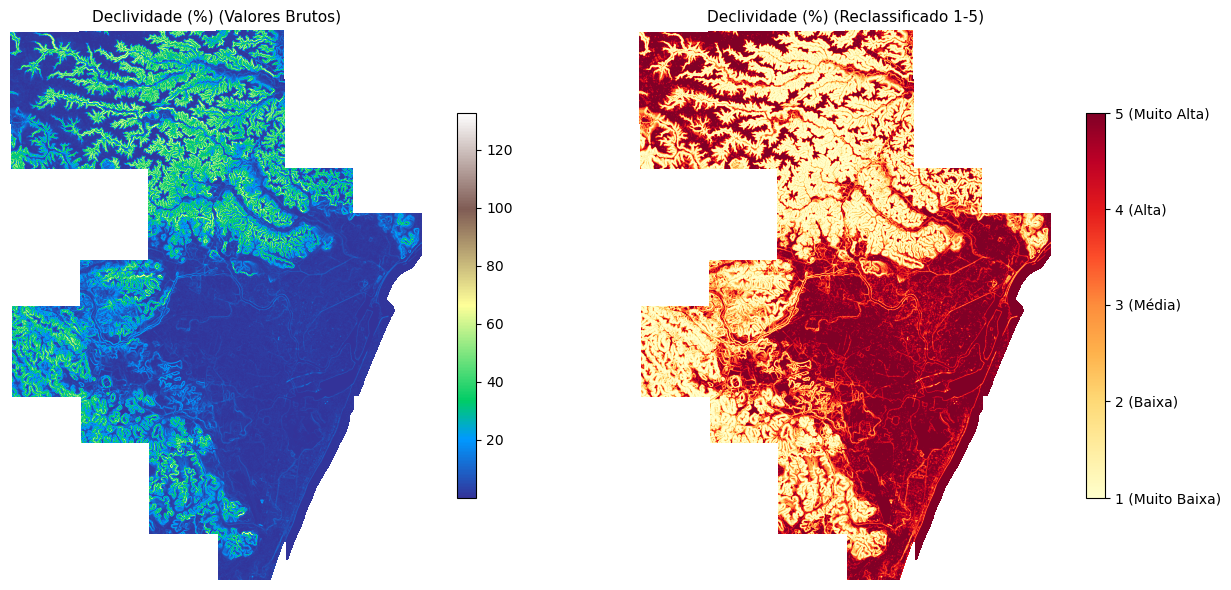

In [17]:
plotar_comparacao(
    array_original=declividade_bruta,
    array_reclassificado=declividade_reclass,
    titulo="Declividade (%)",
    nodata=mdt_info['nodata'],
    cmap_orig="terrain"
)

Raster salvo com sucesso em: ../dados/camadas_rasters/sao-lourenco/declividade.tif


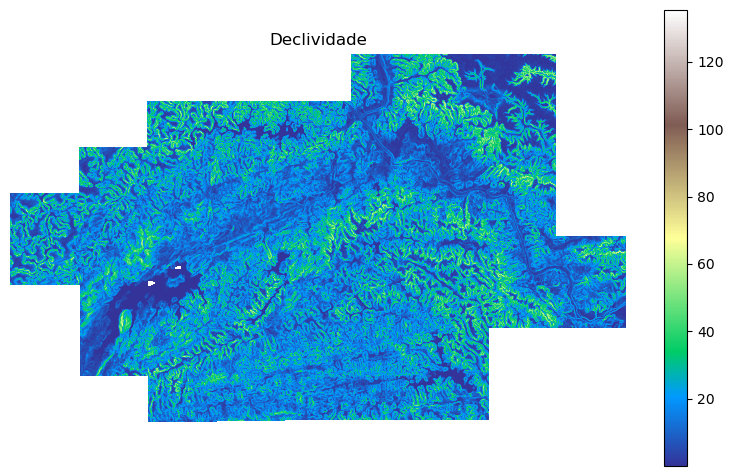

In [10]:
xres, yres = mdt_info['res']

mdt_valido = np.where(mdt_array == mdt_info['nodata'], np.nan, mdt_array)
gy, gx = np.gradient(mdt_valido, yres, xres)
declividade_bruta = np.sqrt(gx**2 + gy**2) * 100.0
declividade_bruta[np.isnan(mdt_valido)] = mdt_info['nodata']

caminho_declividade = '../dados/camadas_rasters/sao-lourenco/declividade.tif'

salvar_raster(declividade_bruta, caminho_declividade, mdt_info)

plotar_raster(declividade_bruta, titulo="Declividade", nodata=mdt_info['nodata'], cmap="terrain")

## Fluxo acumulado

In [24]:
caminho_fluxo_bruto = "../dados/camadas_rasters/fluxo_acumulado.tif"
caminho_fluxo_reclass = "../dados/camadas_rasters/fluxo_acumulado_reclass.tif"


with tempfile.TemporaryDirectory(prefix=f"wbt_fluxo_recife_") as tmp:
    tmp_dir = Path(tmp)
    tmp_mde_nodata = tmp_dir / "mde_nodata.tif"
    tmp_mde_filled = tmp_dir / "mde_filled.tif"
    tmp_out_acc = tmp_dir / "fluxo_acumulado.tif"

    # Prepara o perfil do raster temporário baseado no mdt_info
    profile_tmp = {
        "driver": "GTiff",
        "height": mdt_info["height"],
        "width": mdt_info["width"],
        "count": 1,
        "dtype": rasterio.float32,
        "crs": mdt_info["crs"],
        "transform": mdt_info["transform"],
        "nodata": -9999.0,
    }

    # Trata NaN e substitui o NoData original por -9999.0 para o Whitebox
    mdt_norm = np.where(
        (mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array),
        -9999.0,
        mdt_array,
    )

    # Escreve o MDT da memória direto no temporário
    with rasterio.open(tmp_mde_nodata, "w", **profile_tmp) as dst:
        dst.write(mdt_norm.astype(np.float32), 1)

    # Inicializa o WhiteboxTools
    wbt = WhiteboxTools()
    wbt.verbose = False

    # Copia o binário para o diretório temporário (evita problemas com acentos em caminhos/Google Drive)
    try:
        src_exe_dir = Path(str(wbt.exe_path))
        src_exe = src_exe_dir / "whitebox_tools"
        dst_exe = tmp_dir / "whitebox_tools"
        if src_exe.exists() and not dst_exe.exists():
            shutil.copyfile(src_exe, dst_exe)
            dst_exe.chmod(0o755)
            wbt.exe_path = str(tmp_dir)
    except Exception:
        pass

    wbt.work_dir = str(tmp_dir)

    # Preenche depressões no MDT (Fill Depressions)
    wbt.fill_depressions(
        dem=str(tmp_mde_nodata), output=str(tmp_mde_filled), fix_flats=True
    )

    # Calcula o Fluxo Acumulado D8 (em células)
    wbt.d8_flow_accumulation(
        i=str(tmp_mde_filled), output=str(tmp_out_acc), out_type="cells"
    )

    # Lê a matriz de fluxo acumulado calculada
    with rasterio.open(tmp_out_acc) as src_acc:
        fluxo_bruto = src_acc.read(1)

# Aplica a máscara de NoData do MDT original sobre a matriz do fluxo
fluxo_bruto[
    (mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array)
] = mdt_info["nodata"]

# Salva a camada de fluxo bruto
salvar_raster(fluxo_bruto, caminho_fluxo_bruto, mdt_info)

# Reclassificação usando a estrutura configurada no CONFIG
regras_fluxo = CONFIG["criterios"]["fluxo_acumulado"]["classes"]
fluxo_reclass = reclassificar_raster(
    fluxo_bruto, regras_fluxo, nodata=mdt_info["nodata"]
)

salvar_raster(fluxo_reclass, caminho_fluxo_reclass, mdt_info)

Raster salvo com sucesso em: ../dados/camadas_rasters/fluxo_acumulado.tif
Raster salvo com sucesso em: ../dados/camadas_rasters/fluxo_acumulado_reclass.tif


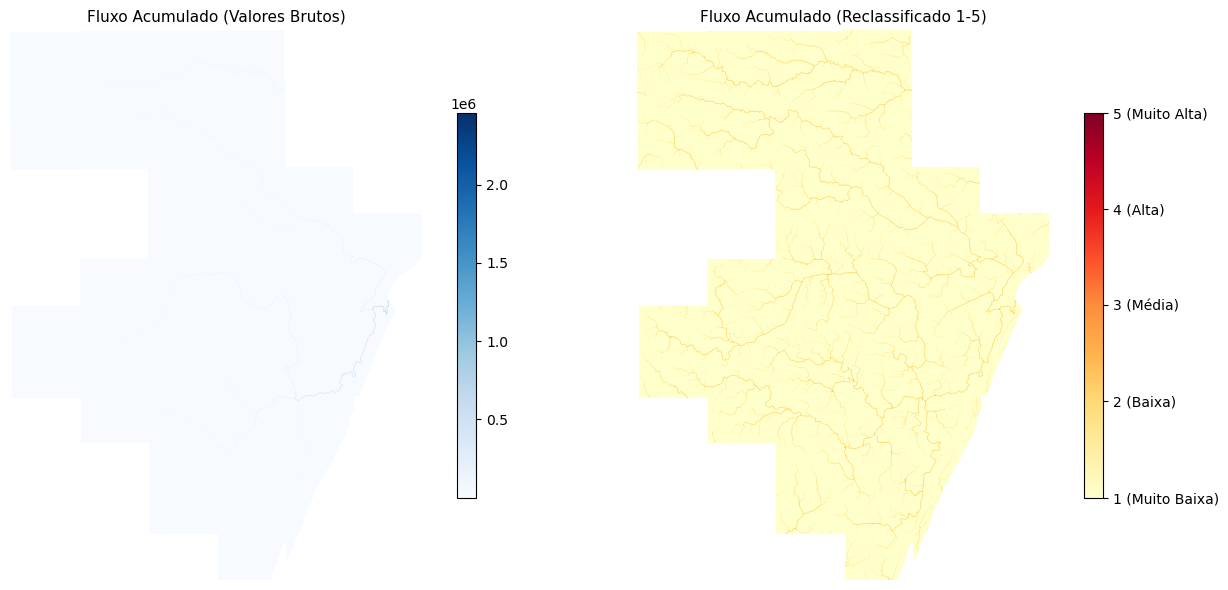

In [25]:
plotar_comparacao(
    array_original=fluxo_bruto,
    array_reclassificado=fluxo_reclass,
    titulo="Fluxo Acumulado",
    nodata=mdt_info["nodata"],
    cmap_orig="Blues",
)

## Uso do solo

In [28]:
from rasterio.enums import Resampling
from rasterio.warp import reproject

caminho_uso_pe = "../dados/camadas_rasters/uso-do-solo-pernambuco-2023.tif"
caminho_uso_bruto = "../dados/camadas_rasters/uso_solo.tif"
caminho_uso_reclass = "../dados/camadas_rasters/uso_solo_reclass.tif"

# Alinhamento e Recorte
uso_solo_recife = np.full(
    (mdt_info["height"], mdt_info["width"]),
    fill_value=mdt_info["nodata"],
    dtype=np.float32,
)

with rasterio.open(caminho_uso_pe) as src_uso:
    reproject(
        source=rasterio.band(src_uso, 1),
        destination=uso_solo_recife,
        src_transform=src_uso.transform,
        src_crs=src_uso.crs,
        dst_transform=mdt_info["transform"],
        dst_crs=mdt_info["crs"],
        resampling=Resampling.nearest,
        dst_nodata=mdt_info["nodata"],
    )

uso_solo_recife[
    (mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array)
] = mdt_info["nodata"]

salvar_raster(uso_solo_recife, caminho_uso_bruto, mdt_info)

# Reclassificação usando o CONFIG de 5 Classes (Baseado nos IDs MapBiomas)
regras_uso = CONFIG["criterios"]["uso_do_solo"]["classes"]

uso_solo_reclass = reclassificar_raster(
    uso_solo_recife, regras_uso, nodata=mdt_info["nodata"]
)

salvar_raster(uso_solo_reclass, caminho_uso_reclass, mdt_info)

Raster salvo com sucesso em: ../dados/camadas_rasters/uso_solo.tif
Raster salvo com sucesso em: ../dados/camadas_rasters/uso_solo_reclass.tif


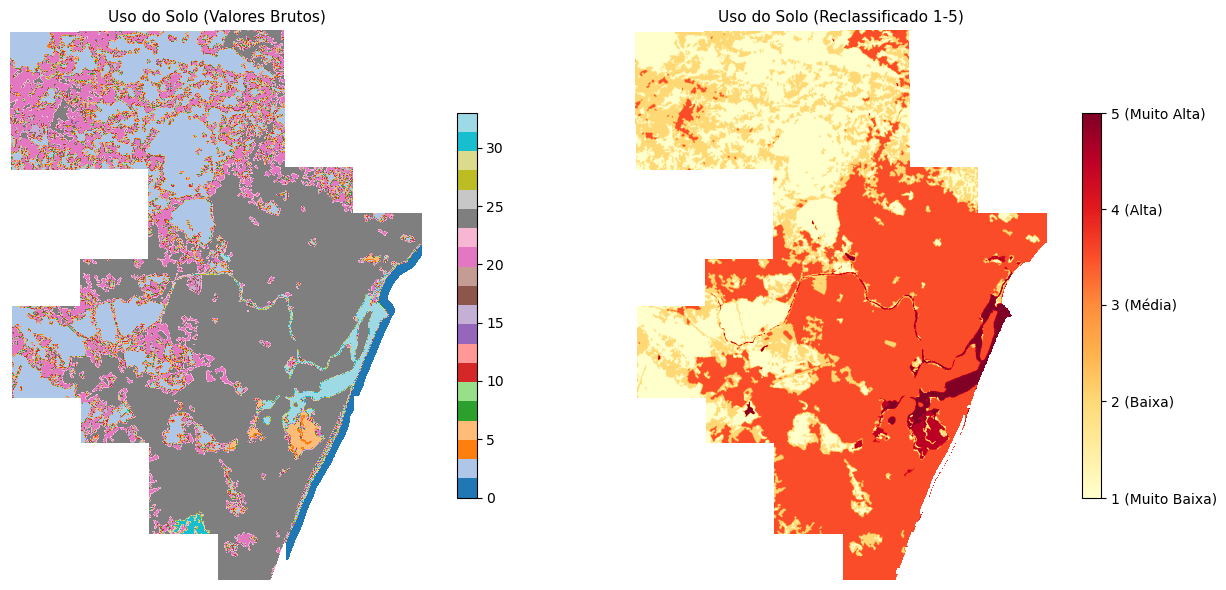

In [30]:
plotar_comparacao(
    array_original=uso_solo_recife,
    array_reclassificado=uso_solo_reclass,
    titulo="Uso do Solo",
    nodata=mdt_info["nodata"],
    cmap_orig="tab20",
)

Raster salvo com sucesso em: ../dados/camadas_rasters/sao-lourenco/uso_solo.tif


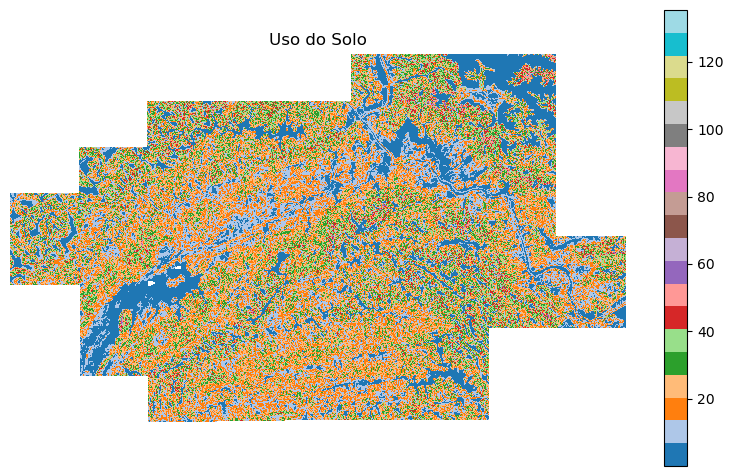

In [11]:
from rasterio.enums import Resampling
from rasterio.warp import reproject

caminho_uso_pe = "../dados/camadas_rasters/uso-do-solo-pernambuco-2023.tif"
caminho_uso_bruto = "../dados/camadas_rasters/sao-lourenco/uso_solo.tif"

uso_solo = np.full(
    (mdt_info["height"], mdt_info["width"]),
    fill_value=mdt_info["nodata"],
    dtype=np.float32,
)

with rasterio.open(caminho_uso_pe) as src_uso:
    reproject(
        source=rasterio.band(src_uso, 1),
        destination=uso_solo,
        src_transform=src_uso.transform,
        src_crs=src_uso.crs,
        dst_transform=mdt_info["transform"],
        dst_crs=mdt_info["crs"],
        resampling=Resampling.nearest,
        dst_nodata=mdt_info["nodata"],
    )

uso_solo[
    (mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array)
] = mdt_info["nodata"]

salvar_raster(uso_solo, caminho_uso_bruto, mdt_info)

plotar_raster(declividade_bruta, titulo="Uso do Solo", nodata=mdt_info['nodata'], cmap="tab20")

## Distância do Rio

In [10]:
caminho_rio = "../dados/capibaribe/malha-rios-recife.shp"
caminho_dist_bruta = "../dados/camadas_rasters/distancia_rio_malha.tif"
caminho_dist_reclass = "../dados/camadas_rasters/distancia_rio_malha_reclass.tif"

rios = gpd.read_file(caminho_rio)
rios = rios.to_crs(mdt_info["crs"])

rio_raster = rasterize(
    [(geom, 1) for geom in rios.geometry if geom is not None],
    out_shape=(mdt_info["height"], mdt_info["width"]),
    transform=mdt_info["transform"],
    fill=0,
    dtype="uint8",
)

pixel_size = abs(mdt_info["res"][0])
distancia_pixels = distance_transform_edt(rio_raster == 0)
distancia_metros = (distancia_pixels * pixel_size).astype(np.float32)

distancia_metros[
    (mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array)
] = mdt_info["nodata"]


salvar_raster(distancia_metros, caminho_dist_bruta, mdt_info)

regras_distancia = CONFIG["criterios"]["distancia_rio"]["classes"]
distancia_reclass = reclassificar_raster(
    distancia_metros, regras_distancia, nodata=mdt_info["nodata"]
)

salvar_raster(distancia_reclass, caminho_dist_reclass, mdt_info)

C:\Users\ezequ\anaconda3\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Raster salvo com sucesso em: ../dados/camadas_rasters/distancia_rio_malha.tif
Raster salvo com sucesso em: ../dados/camadas_rasters/distancia_rio__malha_reclass.tif


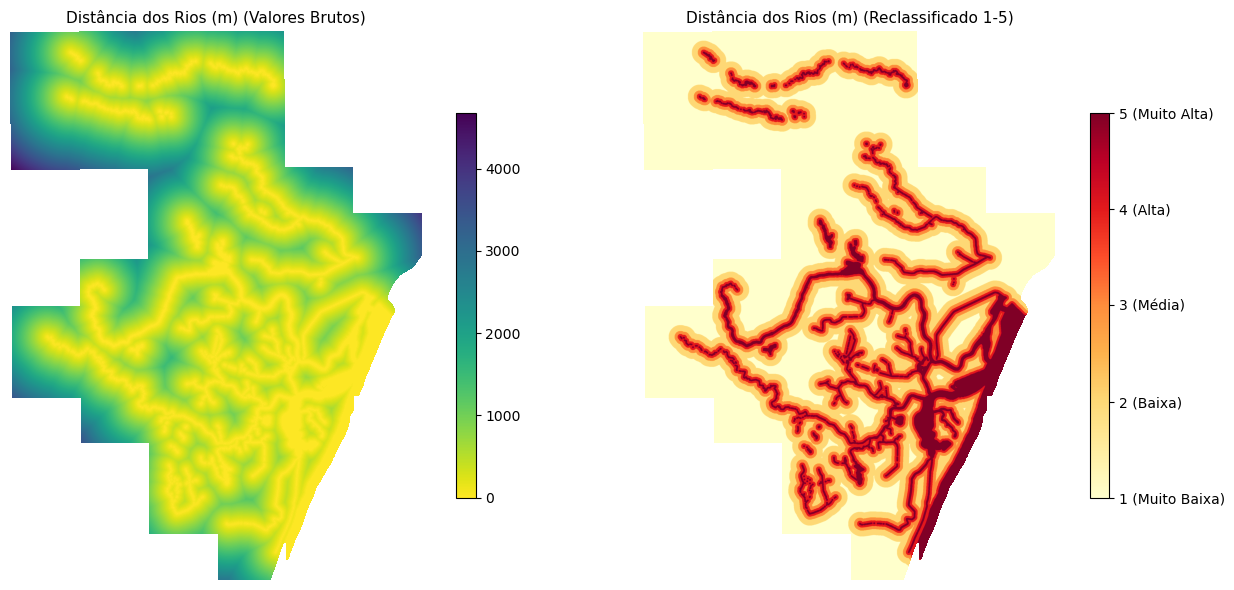

In [11]:
plotar_comparacao(
    array_original=distancia_metros,
    array_reclassificado=distancia_reclass,
    titulo="Distância dos Rios (m)",
    nodata=mdt_info["nodata"],
    cmap_orig="viridis_r",
)

## HAND

In [12]:
caminho_hand_bruto = "../dados/camadas_rasters/hand.tif"
caminho_hand_reclass = "../dados/camadas_rasters/hand_reclass.tif"
caminho_rios_shp = "../dados/capibaribe/malha-rios-recife.shp"

gdf_rios = gpd.read_file(caminho_rios_shp)

# Garante que os rios estão no mesmo sistema de referência (CRS) do MDT
if gdf_rios.crs != mdt_info["crs"]:
    gdf_rios = gdf_rios.to_crs(mdt_info["crs"])

with tempfile.TemporaryDirectory(prefix="wbt_hand_recife_") as tmp:
    tmp_dir = Path(tmp)
    tmp_mde_nodata = tmp_dir / "mde_nodata.tif"
    tmp_mde_filled = tmp_dir / "mde_filled.tif"
    tmp_streams = tmp_dir / "streams.tif"
    tmp_out_hand = tmp_dir / "hand.tif"

    profile_tmp = {
        "driver": "GTiff",
        "height": mdt_info["height"],
        "width": mdt_info["width"],
        "count": 1,
        "dtype": rasterio.float32,
        "crs": mdt_info["crs"],
        "transform": mdt_info["transform"],
        "nodata": -9999.0,
    }

    # Normaliza o MDT e salva
    mdt_norm = np.where(
        (mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array),
        -9999.0,
        mdt_array,
    )
    with rasterio.open(tmp_mde_nodata, "w", **profile_tmp) as dst:
        dst.write(mdt_norm.astype(np.float32), 1)

    # Rasteriza o shapefile dos rios para a mesma grade do MDT
    shapes = [(geom, 1) for geom in gdf_rios.geometry if geom is not None]
    streams_array = rasterize(
        shapes=shapes,
        out_shape=(mdt_info["height"], mdt_info["width"]),
        transform=mdt_info["transform"],
        fill=0,
        dtype=np.uint8,
    )

    profile_streams = profile_tmp.copy()
    profile_streams.update({"dtype": rasterio.uint8, "nodata": 0})

    with rasterio.open(tmp_streams, "w", **profile_streams) as dst:
        dst.write(streams_array, 1)

    wbt = WhiteboxTools()
    wbt.verbose = False

    try:
        src_exe = Path(str(wbt.exe_path)) / "whitebox_tools"
        dst_exe = tmp_dir / "whitebox_tools"
        if src_exe.exists() and not dst_exe.exists():
            shutil.copyfile(src_exe, dst_exe)
            dst_exe.chmod(0o755)
            wbt.exe_path = str(tmp_dir)
    except Exception:
        pass

    wbt.work_dir = str(tmp_dir)

    # Preenche depressões do MDT
    wbt.fill_depressions(dem=str(tmp_mde_nodata), output=str(tmp_mde_filled), fix_flats=True)

    # Executa o HAND usando o raster gerado a partir do shapefile
    wbt.elevation_above_stream(
        dem=str(tmp_mde_filled),
        streams=str(tmp_streams),
        output=str(tmp_out_hand)
    )

    with rasterio.open(tmp_out_hand) as src_hand:
        hand_bruto = src_hand.read(1)

# Trata áreas NoData
hand_bruto[(mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array)] = mdt_info["nodata"]

# Salva e reclassifica
salvar_raster(hand_bruto, caminho_hand_bruto, mdt_info)

regras_hand = CONFIG["criterios"]["hand"]["classes"]
hand_reclass = reclassificar_raster(hand_bruto, regras_hand, nodata=mdt_info["nodata"])
salvar_raster(hand_reclass, caminho_hand_reclass, mdt_info)

Raster salvo com sucesso em: ../dados/camadas_rasters/hand.tif
Raster salvo com sucesso em: ../dados/camadas_rasters/hand_reclass.tif


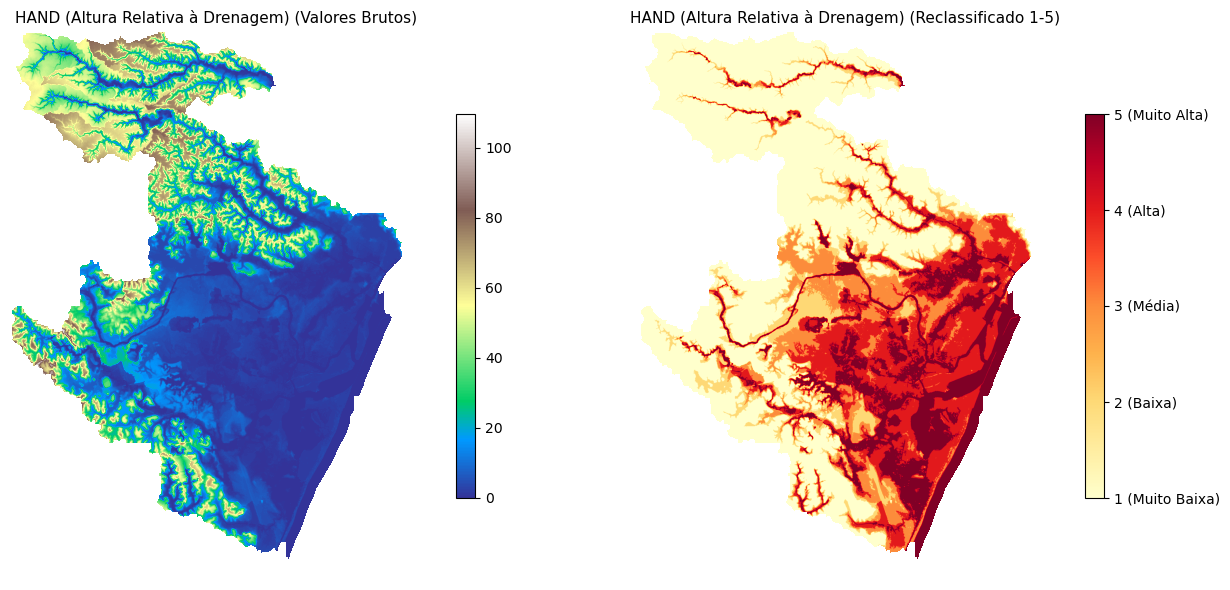

In [13]:
plotar_comparacao(
    array_original=hand_bruto,
    array_reclassificado=hand_reclass,
    titulo="HAND (Altura Relativa à Drenagem)",
    nodata=mdt_info["nodata"],
    cmap_orig="terrain",
)

In [10]:
caminho_hand_bruto = "../dados/camadas_rasters/sao-lourenco/hand.tif"
caminho_rios_shp = "../dados/capibaribe/Rio_Principal_CAP_25S.shp"

gdf_rios = gpd.read_file(caminho_rios_shp)

# Garante que os rios estão no mesmo sistema de referência (CRS) do MDT
if gdf_rios.crs != mdt_info["crs"]:
    gdf_rios = gdf_rios.to_crs(mdt_info["crs"])

with tempfile.TemporaryDirectory(prefix="wbt_hand_recife_") as tmp:
    tmp_dir = Path(tmp)
    tmp_mde_nodata = tmp_dir / "mde_nodata.tif"
    tmp_mde_filled = tmp_dir / "mde_filled.tif"
    tmp_streams = tmp_dir / "streams.tif"
    tmp_out_hand = tmp_dir / "hand.tif"

    profile_tmp = {
        "driver": "GTiff",
        "height": mdt_info["height"],
        "width": mdt_info["width"],
        "count": 1,
        "dtype": rasterio.float32,
        "crs": mdt_info["crs"],
        "transform": mdt_info["transform"],
        "nodata": -9999.0,
    }

    # Normaliza o MDT e salva
    mdt_norm = np.where(
        (mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array),
        -9999.0,
        mdt_array,
    )
    with rasterio.open(tmp_mde_nodata, "w", **profile_tmp) as dst:
        dst.write(mdt_norm.astype(np.float32), 1)

    # Rasteriza o shapefile dos rios para a mesma grade do MDT
    shapes = [(geom, 1) for geom in gdf_rios.geometry if geom is not None]
    streams_array = rasterize(
        shapes=shapes,
        out_shape=(mdt_info["height"], mdt_info["width"]),
        transform=mdt_info["transform"],
        fill=0,
        dtype=np.uint8,
    )

    profile_streams = profile_tmp.copy()
    profile_streams.update({"dtype": rasterio.uint8, "nodata": 0})

    with rasterio.open(tmp_streams, "w", **profile_streams) as dst:
        dst.write(streams_array, 1)

    wbt = WhiteboxTools()
    wbt.verbose = False

    try:
        src_exe = Path(str(wbt.exe_path)) / "whitebox_tools"
        dst_exe = tmp_dir / "whitebox_tools"
        if src_exe.exists() and not dst_exe.exists():
            shutil.copyfile(src_exe, dst_exe)
            dst_exe.chmod(0o755)
            wbt.exe_path = str(tmp_dir)
    except Exception:
        pass

    wbt.work_dir = str(tmp_dir)

    # Preenche depressões do MDT
    wbt.fill_depressions(dem=str(tmp_mde_nodata), output=str(tmp_mde_filled), fix_flats=True)

    # Executa o HAND usando o raster gerado a partir do shapefile
    wbt.elevation_above_stream(
        dem=str(tmp_mde_filled),
        streams=str(tmp_streams),
        output=str(tmp_out_hand)
    )

    with rasterio.open(tmp_out_hand) as src_hand:
        hand_bruto = src_hand.read(1)

# Trata áreas NoData
hand_bruto[(mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array)] = mdt_info["nodata"]

# Salva e reclassifica
salvar_raster(hand_bruto, caminho_hand_bruto, mdt_info)

C:\Users\ezequ\anaconda3\Lib\site-packages\pyogrio\core.py:35: RuntimeWarning: Could not detect GDAL data files.  Set GDAL_DATA environment variable to the correct path.
  _init_gdal_data()


Raster salvo com sucesso em: ../dados/camadas_rasters/sao-lourenco/hand.tif


## TWI

In [43]:
caminho_twi_bruto = "../dados/camadas_rasters/twi.tif"
caminho_twi_reclass = "../dados/camadas_rasters/twi_reclass.tif"


with tempfile.TemporaryDirectory(prefix="wbt_twi_recife_") as tmp:
    tmp_dir = Path(tmp)
    tmp_mde_nodata = tmp_dir / "mde_nodata.tif"
    tmp_mde_filled = tmp_dir / "mde_filled.tif"
    tmp_slope = tmp_dir / "slope.tif"
    tmp_flow_accum = tmp_dir / "flow_accum.tif"
    tmp_out_twi = tmp_dir / "twi.tif"

    profile_tmp = {
        "driver": "GTiff",
        "height": mdt_info["height"],
        "width": mdt_info["width"],
        "count": 1,
        "dtype": rasterio.float32,
        "crs": mdt_info["crs"],
        "transform": mdt_info["transform"],
        "nodata": -9999.0,
    }

    mdt_norm = np.where(
        (mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array),
        -9999.0,
        mdt_array,
    )
    with rasterio.open(tmp_mde_nodata, "w", **profile_tmp) as dst:
        dst.write(mdt_norm.astype(np.float32), 1)

    wbt = WhiteboxTools()
    wbt.verbose = False

    try:
        src_exe = Path(str(wbt.exe_path)) / "whitebox_tools"
        dst_exe = tmp_dir / "whitebox_tools"
        if src_exe.exists() and not dst_exe.exists():
            shutil.copyfile(src_exe, dst_exe)
            dst_exe.chmod(0o755)
            wbt.exe_path = str(tmp_dir)
    except Exception:
        pass

    wbt.work_dir = str(tmp_dir)

    # Preenchimento de depressões
    wbt.fill_depressions(dem=str(tmp_mde_nodata), output=str(tmp_mde_filled), fix_flats=True)

    # Declividade em graus
    wbt.slope(dem=str(tmp_mde_filled), output=str(tmp_slope), units="degrees")

    # Acúmulo de Fluxo em área (sca = specific catchment area)
    wbt.d8_flow_accumulation(i=str(tmp_mde_filled), output=str(tmp_flow_accum), out_type="sca")

    # Cálculo do TWI (Wetness Index)
    wbt.wetness_index(
        sca=str(tmp_flow_accum),
        slope=str(tmp_slope),
        output=str(tmp_out_twi)
    )

    with rasterio.open(tmp_out_twi) as src_twi:
        twi_bruto = src_twi.read(1)

twi_bruto[(mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array)] = mdt_info["nodata"]

salvar_raster(twi_bruto, caminho_twi_bruto, mdt_info)

regras_twi = CONFIG["criterios"]["twi"]["classes"]
twi_reclass = reclassificar_raster(twi_bruto, regras_twi, nodata=mdt_info["nodata"])

salvar_raster(twi_reclass, caminho_twi_reclass, mdt_info)

Raster salvo com sucesso em: ../dados/camadas_rasters/twi.tif
Raster salvo com sucesso em: ../dados/camadas_rasters/twi_reclass.tif


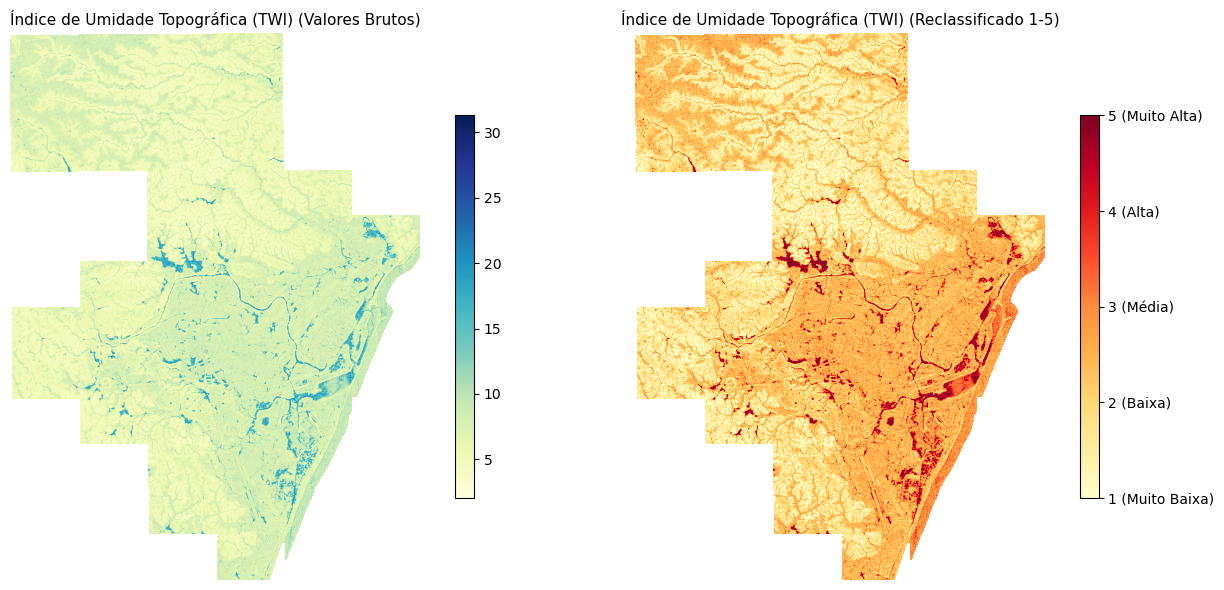

In [44]:
plotar_comparacao(
    array_original=twi_bruto,
    array_reclassificado=twi_reclass,
    titulo="Índice de Umidade Topográfica (TWI)",
    nodata=mdt_info["nodata"],
    cmap_orig="YlGnBu",
)

In [12]:
caminho_twi_bruto = "../dados/camadas_rasters/sao-lourenco/twi.tif"


with tempfile.TemporaryDirectory(prefix="wbt_twi_sao_lourenco_") as tmp:
    tmp_dir = Path(tmp)
    tmp_mde_nodata = tmp_dir / "mde_nodata.tif"
    tmp_mde_filled = tmp_dir / "mde_filled.tif"
    tmp_slope = tmp_dir / "slope.tif"
    tmp_flow_accum = tmp_dir / "flow_accum.tif"
    tmp_out_twi = tmp_dir / "twi.tif"

    profile_tmp = {
        "driver": "GTiff",
        "height": mdt_info["height"],
        "width": mdt_info["width"],
        "count": 1,
        "dtype": rasterio.float32,
        "crs": mdt_info["crs"],
        "transform": mdt_info["transform"],
        "nodata": -9999.0,
    }

    mdt_norm = np.where(
        (mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array),
        -9999.0,
        mdt_array,
    )
    with rasterio.open(tmp_mde_nodata, "w", **profile_tmp) as dst:
        dst.write(mdt_norm.astype(np.float32), 1)

    wbt = WhiteboxTools()
    wbt.verbose = False

    try:
        src_exe = Path(str(wbt.exe_path)) / "whitebox_tools"
        dst_exe = tmp_dir / "whitebox_tools"
        if src_exe.exists() and not dst_exe.exists():
            shutil.copyfile(src_exe, dst_exe)
            dst_exe.chmod(0o755)
            wbt.exe_path = str(tmp_dir)
    except Exception:
        pass

    wbt.work_dir = str(tmp_dir)

    # Preenchimento de depressões
    wbt.fill_depressions(dem=str(tmp_mde_nodata), output=str(tmp_mde_filled), fix_flats=True)

    # Declividade em graus
    wbt.slope(dem=str(tmp_mde_filled), output=str(tmp_slope), units="degrees")

    # Acúmulo de Fluxo em área (sca = specific catchment area)
    wbt.d8_flow_accumulation(i=str(tmp_mde_filled), output=str(tmp_flow_accum), out_type="sca")

    # Cálculo do TWI (Wetness Index)
    wbt.wetness_index(
        sca=str(tmp_flow_accum),
        slope=str(tmp_slope),
        output=str(tmp_out_twi)
    )

    with rasterio.open(tmp_out_twi) as src_twi:
        twi_bruto = src_twi.read(1)

twi_bruto[(mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array)] = mdt_info["nodata"]

salvar_raster(twi_bruto, caminho_twi_bruto, mdt_info)

Raster salvo com sucesso em: ../dados/camadas_rasters/sao-lourenco/twi.tif


## Pluviometria

In [1]:
caminho_csv_chuvas = "../dados/pluviometria/dados_estacoes_apac.csv"
caminho_chuva_bruta = "../dados/camadas_rasters/precipitacao.tif"
caminho_chuva_reclass = "../dados/camadas_rasters/precipitacao_reclass.tif"

df_raw = pd.read_csv(caminho_csv_chuvas)

df_raw.columns = df_raw.iloc[0]
df_chuvas = df_raw[1:].copy()

meses = [
    'Janeiro', 'Fevereiro', 'Marco', 'Abril', 'Maio', 'Junho', 
    'Julho', 'Agosto', 'Setembro', 'Outubro', 'Novembro', 'Dezembro'
]

for col in meses:
    df_chuvas[col] = (
        df_chuvas[col]
        .astype(str)
        .str.replace('-', '')
        .str.replace(',', '.')
        .replace('', np.nan)
        .astype(float)
    )

# Calcula o acumulado do ano e a contagem de meses com medição
df_chuvas['Total_Ano'] = df_chuvas[meses].sum(axis=1, skipna=True)
df_chuvas['Meses_Validos'] = df_chuvas[meses].notna().sum(axis=1)

# Filtra apenas anos consistentes (pelo menos 10 meses medidos no ano)
df_validos = df_chuvas[df_chuvas['Meses_Validos'] >= 10]

# Média Anual Acumulada da série histórica por estação
df_medias = df_validos.groupby('Posto')['Total_Ano'].mean().reset_index()
df_medias.columns = ['Posto', 'precipitacao_mm']

coordenadas_estacoes = {
    'Recife (Alto da Brasileira)': {'latitude': -8.001, 'longitude': -34.935},
    'Recife (Lamepe/Itep)':        {'latitude': -8.057, 'longitude': -34.952},
    'Recife (Várzea)':             {'latitude': -8.050, 'longitude': -34.970},
    'Recife (Santo Amaro)':        {'latitude': -8.050, 'longitude': -34.880}
}

df_medias['latitude'] = df_medias['Posto'].map(lambda x: coordenadas_estacoes[x]['latitude'])
df_medias['longitude'] = df_medias['Posto'].map(lambda x: coordenadas_estacoes[x]['longitude'])


gdf_chuvas = gpd.GeoDataFrame(
    df_medias, 
    geometry=gpd.points_from_xy(df_medias.longitude, df_medias.latitude),
    crs="EPSG:4326"
)

gdf_chuvas = gdf_chuvas.to_crs(mdt_info["crs"])

coords_pontos = np.column_stack((gdf_chuvas.geometry.x, gdf_chuvas.geometry.y))
valores_chuva = gdf_chuvas["precipitacao_mm"].values

height, width = mdt_info["height"], mdt_info["width"]
transform = mdt_info["transform"]

cols, rows = np.meshgrid(np.arange(width), np.arange(height))
xs, ys = rasterio.transform.xy(transform, rows, cols)
coords_grid = np.column_stack((np.array(xs).flatten(), np.array(ys).flatten()))

def calcular_idw(coords_amostra, valores_amostra, coords_destino, power=2.0):
    dist = distance_matrix(coords_destino, coords_amostra)
    dist = np.where(dist == 0, 1e-10, dist)
    
    pesos = 1.0 / (dist ** power)
    pesos_soma = np.sum(pesos, axis=1, keepdims=True)
    
    idw_flat = np.sum(pesos * valores_amostra, axis=1, keepdims=True) / pesos_soma
    return idw_flat.reshape((height, width))

chuva_bruta = calcular_idw(coords_pontos, valores_chuva, coords_grid, power=2.0).astype(np.float32)

chuva_bruta[(mdt_array == mdt_info["nodata"]) | np.isnan(mdt_array)] = mdt_info["nodata"]

salvar_raster(chuva_bruta, caminho_chuva_bruta, mdt_info)

chuva_mensal = chuva_bruta / 12.0

regras_chuva = CONFIG["criterios"]["pluviometria"]["classes"]
chuva_reclass = reclassificar_raster(chuva_mensal, regras_chuva, nodata=mdt_info["nodata"])

salvar_raster(chuva_reclass, caminho_chuva_reclass, mdt_info)

NameError: name 'pd' is not defined

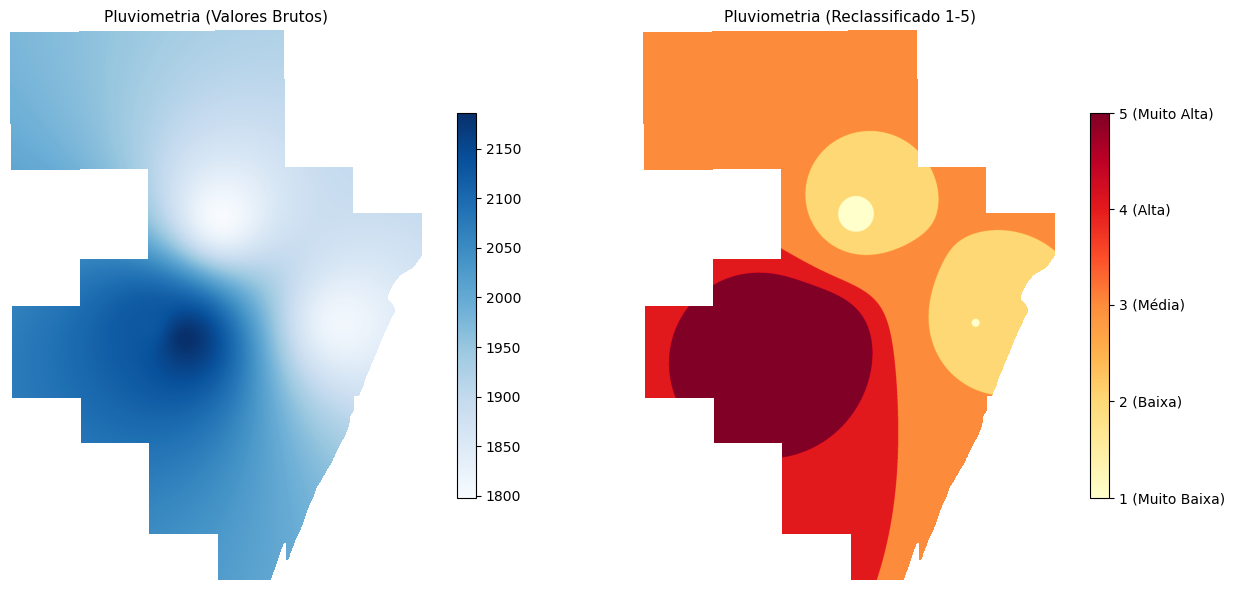

In [20]:
plotar_comparacao(
    array_original=chuva_bruta,
    array_reclassificado=chuva_reclass,
    titulo="Pluviometria",
    nodata=mdt_info["nodata"],
    cmap_orig="Blues",
)

## Pedologia

In [16]:
mdt_path = '../dados/camadas_rasters/mdt_recife_pe3d_10m.tif'
pedo_path = '../dados/pedologia/pedo_area.shp'
output_path = '../dados/camadas_rasters/pedologia.tif'
temp_output_path = '../dados/camadas_rasters/pedologia_temp.tif'

with rasterio.open(mdt_path) as src:
    crs_mdt = src.crs
    bounds_mdt = src.bounds
    
    mdt_info = {
        "perfil": src.profile,
        "crs": src.crs,
        "transform": src.transform,
        "width": src.width,
        "height": src.height,
        "nodata": src.nodata if src.nodata is not None else -9999
    }

bbox_geom = box(*bounds_mdt)
bbox_gdf = gpd.GeoDataFrame(geometry=[bbox_geom], crs=crs_mdt)

pedo_gdf = gpd.read_file(pedo_path)

if pedo_gdf.crs != crs_mdt:
    pedo_gdf = pedo_gdf.to_crs(crs_mdt)

pedo_recortado = gpd.clip(pedo_gdf, bbox_gdf)

coluna_valor = 'cod_simbol'

if pedo_recortado[coluna_valor].dtype == 'object':
    pedo_recortado['id_numerico'] = pedo_recortado[coluna_valor].astype('category').cat.codes + 1
    coluna_raster = 'id_numerico'
    
    mapeamento = dict(enumerate(pedo_recortado[coluna_valor].astype('category').cat.categories))
    print("Mapeamento das classes de solo:", mapeamento)
else:
    coluna_raster = coluna_valor

shapes = [(geom, valor) for geom, valor in zip(pedo_recortado.geometry, pedo_recortado[coluna_raster].astype(np.float32))]

if shapes:
    raster_solos_bruto = rasterize(
        shapes=shapes,
        out_shape=(mdt_info['height'], mdt_info['width']),
        transform=mdt_info['transform'],
        fill=mdt_info['nodata'],
        dtype=np.float32
    )
else:
    raster_solos_bruto = np.full((mdt_info['height'], mdt_info['width']), mdt_info['nodata'], dtype=np.float32)

salvar_raster(raster_solos_bruto, temp_output_path, mdt_info, dtype='float32')

raster_alinhado = alinhar_raster_ao_mdt(
    caminho_raster_entrada=temp_output_path,
    mdt_meta=mdt_info,
    resampling_mode=Resampling.nearest
)

salvar_raster(raster_alinhado, output_path, mdt_info, dtype='float32')

if os.path.exists(temp_output_path):
    os.remove(temp_output_path)

Mapeamento das classes de solo: {0: 'GJo', 1: 'LAd', 2: 'LAdx', 3: 'PVAd', 4: 'RYbd', 5: 'RYve'}
Raster salvo com sucesso em: ../dados/camadas_rasters/pedologia_temp.tif
Raster salvo com sucesso em: ../dados/camadas_rasters/pedologia.tif


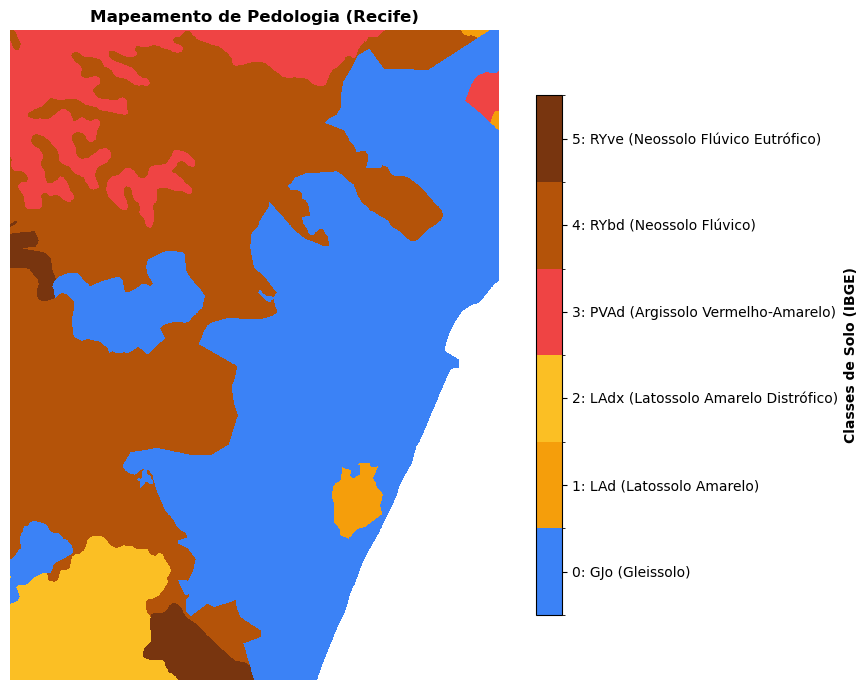

In [12]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np


pedo_path = '../dados/camadas_rasters/pedologia.tif'

cores_personalizadas = [
    '#3b82f6',  # 0: GJo (Gleissolo)
    '#f59e0b',  # 1: LAd (Latossolo Amarelo)
    '#fbbf24',  # 2: LAdx (Latossolo Amarelo Distrófico)
    '#ef4444',  # 3: PVAd (Argissolo Vermelho-Amarelo)
    '#b45309',  # 4: RYbd (Neossolo Flúvico)
    '#78350f'   # 5: RYve (Neossolo Flúvico Eutrófico)
]

cmap_personalizado = mcolors.ListedColormap(cores_personalizadas)

# Define os limites exatos para cada classe inteira
bounds = [-0.5, 0.5, 1.5, 2.5, 3.5, 4.5, 5.5]
norm = mcolors.BoundaryNorm(bounds, cmap_personalizado.N)

with rasterio.open(pedo_path) as src:
    array_solos = src.read(1)
    nodata_val = src.nodata if src.nodata is not None else -9999

solos_masked = np.ma.masked_equal(array_solos, nodata_val)
solos_masked = np.ma.masked_where(np.isnan(solos_masked), solos_masked)

fig, ax = plt.subplots(figsize=(10, 7))

im = ax.imshow(
    solos_masked, 
    cmap=cmap_personalizado, 
    norm=norm, 
    interpolation='nearest'
)

ax.set_title("Mapeamento de Pedologia (Recife)", fontsize=12, fontweight='bold')

cbar = plt.colorbar(im, ax=ax, shrink=0.8, ticks=range(6))
cbar.set_label("Classes de Solo (IBGE)", fontsize=10, fontweight='bold')

cbar.set_ticks(range(6))
cbar.set_ticklabels([
    "0: GJo (Gleissolo)",
    "1: LAd (Latossolo Amarelo)",
    "2: LAdx (Latossolo Amarelo Distrófico)",
    "3: PVAd (Argissolo Vermelho-Amarelo)",
    "4: RYbd (Neossolo Flúvico)",
    "5: RYve (Neossolo Flúvico Eutrófico)"
])

ax.axis("off")
plt.tight_layout()
plt.show()

In [14]:
mdt_path = '../dados/camadas_rasters/sao-lourenco/mdt_sao_lourenco_pe3d_10m.tif'
pedo_path = '../dados/pedologia/pedo_area.shp'
output_path = '../dados/camadas_rasters/sao-lourenco/pedologia.tif'
temp_output_path = '../dados/camadas_rasters/sao-lourenco/pedologia_temp.tif'

with rasterio.open(mdt_path) as src:
    crs_mdt = src.crs
    bounds_mdt = src.bounds
    
    mdt_info = {
        "perfil": src.profile,
        "crs": src.crs,
        "transform": src.transform,
        "width": src.width,
        "height": src.height,
        "nodata": src.nodata if src.nodata is not None else -9999
    }

bbox_geom = box(*bounds_mdt)
bbox_gdf = gpd.GeoDataFrame(geometry=[bbox_geom], crs=crs_mdt)

pedo_gdf = gpd.read_file(pedo_path)

if pedo_gdf.crs != crs_mdt:
    pedo_gdf = pedo_gdf.to_crs(crs_mdt)

pedo_recortado = gpd.clip(pedo_gdf, bbox_gdf)

coluna_valor = 'cod_simbol'

if pedo_recortado[coluna_valor].dtype == 'object':
    pedo_recortado['id_numerico'] = pedo_recortado[coluna_valor].astype('category').cat.codes + 1
    coluna_raster = 'id_numerico'
    
    mapeamento = dict(enumerate(pedo_recortado[coluna_valor].astype('category').cat.categories))
    print("Mapeamento das classes de solo:", mapeamento)
else:
    coluna_raster = coluna_valor

shapes = [(geom, valor) for geom, valor in zip(pedo_recortado.geometry, pedo_recortado[coluna_raster].astype(np.float32))]

if shapes:
    raster_solos_bruto = rasterize(
        shapes=shapes,
        out_shape=(mdt_info['height'], mdt_info['width']),
        transform=mdt_info['transform'],
        fill=mdt_info['nodata'],
        dtype=np.float32
    )
else:
    raster_solos_bruto = np.full((mdt_info['height'], mdt_info['width']), mdt_info['nodata'], dtype=np.float32)

salvar_raster(raster_solos_bruto, temp_output_path, mdt_info, dtype='float32')

raster_alinhado = alinhar_raster_ao_mdt(
    caminho_raster_entrada=temp_output_path,
    mdt_meta=mdt_info,
    resampling_mode=Resampling.nearest
)

salvar_raster(raster_alinhado, output_path, mdt_info, dtype='float32')

if os.path.exists(temp_output_path):
    os.remove(temp_output_path)

Mapeamento das classes de solo: {0: 'LAd', 1: 'LAdx', 2: 'PVAd', 3: 'PVAe', 4: 'RYve', 5: 'TCo'}
Raster salvo com sucesso em: ../dados/camadas_rasters/sao-lourenco/pedologia_temp.tif
Raster salvo com sucesso em: ../dados/camadas_rasters/sao-lourenco/pedologia.tif
